In [1]:
# ライブラリのインポート
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# データの読み込み
df = pd.read_csv("garnet.csv")

# 記述子の抽出: No, Compound は識別子なので除外
feature_cols = [col for col in df.columns if col not in ["No", "Compound"]]
X = df[feature_cols].copy()

# 標準化
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
df_scaled = pd.DataFrame(X_scaled, columns=feature_cols, index=df.index)

# PCAの実行
pca = PCA()
pca.fit(X_scaled)
pca_score = pca.transform(X_scaled)
pca_col = [f"PC{i + 1}" for i in range(len(feature_cols))]

各主成分の寄与率
        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0  0.397973  0.282378  0.121098  0.078908  0.057954  0.026361  0.018443   

      PC8       PC9  
0  0.0123  0.004585  


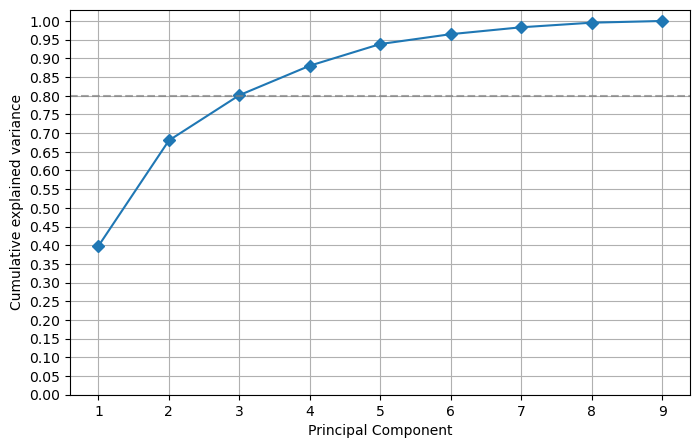

In [2]:
# 寄与率を求める
df_con_ratio = pd.DataFrame([pca.explained_variance_ratio_], columns=pca_col)
print("各主成分の寄与率")
print(df_con_ratio.head())

cum_con_ratio = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_con_ratio) + 1), cum_con_ratio, 'D-', color='tab:blue')
plt.axhline(0.8, color='gray', linestyle='--', alpha=0.7)
plt.xticks(range(1, min(10, len(cum_con_ratio)) + 1))
plt.yticks(np.arange(0, 1.05, 0.05))
plt.xlabel("Principal Component")
plt.ylabel("Cumulative explained variance")
plt.grid(True)
plt.show()

主成分負荷量
          PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
RA  -0.193549 -0.361222  0.145630  0.828586 -0.093651 -0.165806 -0.248727   
RB  -0.381238 -0.268281  0.365739  0.045327  0.260406  0.523576  0.522838   
RC   0.345963 -0.308991  0.019554 -0.050377  0.735752 -0.364833  0.166518   
ENA  0.094314  0.487278  0.478256  0.212354  0.202765 -0.339935  0.023408   
ENB  0.441110  0.062200 -0.259393  0.269759  0.317310  0.609488 -0.345936   

          PC8       PC9  
RA  -0.125121  0.102528  
RB   0.176743  0.017943  
RC  -0.257859  0.115158  
ENA  0.551692 -0.135136  
ENB  0.263939 -0.001417  


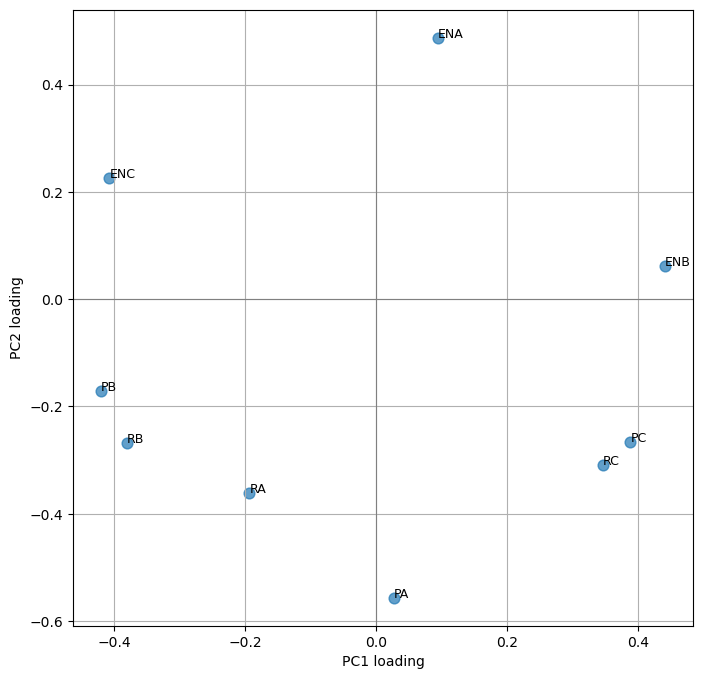

In [3]:
# 主成分負荷量を求める
df_loading = pd.DataFrame(pca.components_.T, index=feature_cols, columns=pca_col)
print("主成分負荷量")
print(df_loading.head())

# 2次元負荷量の可視化
plt.figure(figsize=(8, 8))
for i, feature in enumerate(feature_cols):
    x, y = pca.components_[0, i], pca.components_[1, i]
    plt.text(x, y, feature, fontsize=9)
plt.scatter(pca.components_[0], pca.components_[1], s=60, alpha=0.7)
plt.axhline(0, color='gray', lw=0.8)
plt.axvline(0, color='gray', lw=0.8)
plt.xlabel("PC1 loading")
plt.ylabel("PC2 loading")
plt.grid(True)
plt.show()

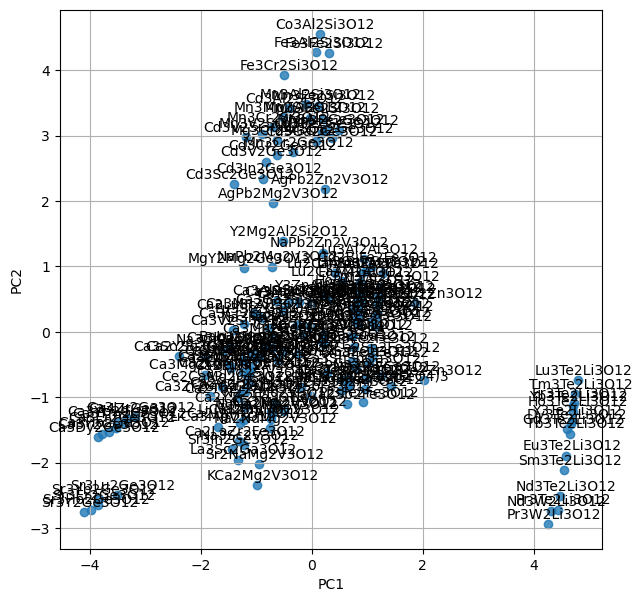

In [4]:
# 主成分得点を求める
df_score = pd.DataFrame(pca_score[:, :2], columns=["PC1", "PC2"], index=df.index)
df_score["Compound"] = df["Compound"]

plt.figure(figsize=(7, 7))
plt.scatter(df_score["PC1"], df_score["PC2"], alpha=0.8)
for idx, row in df_score.iterrows():
    plt.annotate(row["Compound"], (row["PC1"], row["PC2"]), textcoords="offset points", xytext=(4, 4), ha='center')
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.show()

# CSV保存
df_score.to_csv("pca_scores_standardized.csv", index=False)

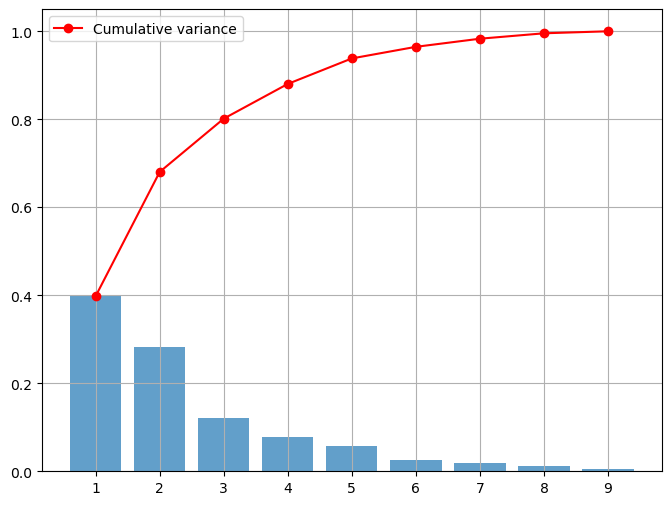

In [5]:
# 寄与率の棒グラフと累積線
top_n = min(9, len(pca.explained_variance_ratio_))
explained_variance = pca.explained_variance_ratio_[:top_n]

plt.figure(figsize=(8, 6))
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.7)
plt.plot(range(1, len(explained_variance) + 1), np.cumsum(explained_variance), color='red', marker='o', label='Cumulative variance')
plt.xticks(range(1, len(explained_variance) + 1))
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

In [6]:
# 実行結果の確認
print("標準化後のデータ形状:", X_scaled.shape)
print("第1主成分の寄与率:", round(pca.explained_variance_ratio_[0], 4))
print("累積寄与率(上位3成分):", np.round(np.cumsum(pca.explained_variance_ratio_[:3]), 4).tolist())

標準化後のデータ形状: (175, 9)
第1主成分の寄与率: 0.398
累積寄与率(上位3成分): [0.398, 0.6804, 0.8014]
